# 🧪 LAB: Clustering several real datasets

**Motivation**: This lab adopts three contrasting datasets to illustrate how clustering behaves under different real-world conditions—differences in scale, varying cluster separations, and high-dimensional gene expression data. You will put these concepts into practice by applying different clustering methods and evaluating how well they uncover structure in each dataset.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Kaitlin Luu, Natalie Schweickert, James Torgerson"

## Part 1: Clustering arrests by U.S. state (25 points)

The dataset below contains statistics for the 50 U.S. states on four variables recorded in 1973:

- Murder: Arrests for murder (per 100,000 residents)
- Assault: Arrests for assault (per 100,000 residents)
- UrbanPop: Percentage of urban population
- Rape: Arrests for rape (per 100,000 residents)

In [20]:
import pandas as pd 
dat_1 = pd.read_csv("Lab08-part1_data.csv")
states = dat_1.state.to_list()
X = dat_1.drop(columns="state")
X.head() # This is the dataset to use

,Murder,Assault,UrbanPop,Rape
0,13.2,236,58,21.2
1,10.0,263,48,44.5
2,8.1,294,80,31.0
3,8.8,190,50,19.5
4,9.0,276,91,40.6


1. Perform hierarchical clustering using complete linkage and Euclidean distance. Plot the resulting dendrogram.

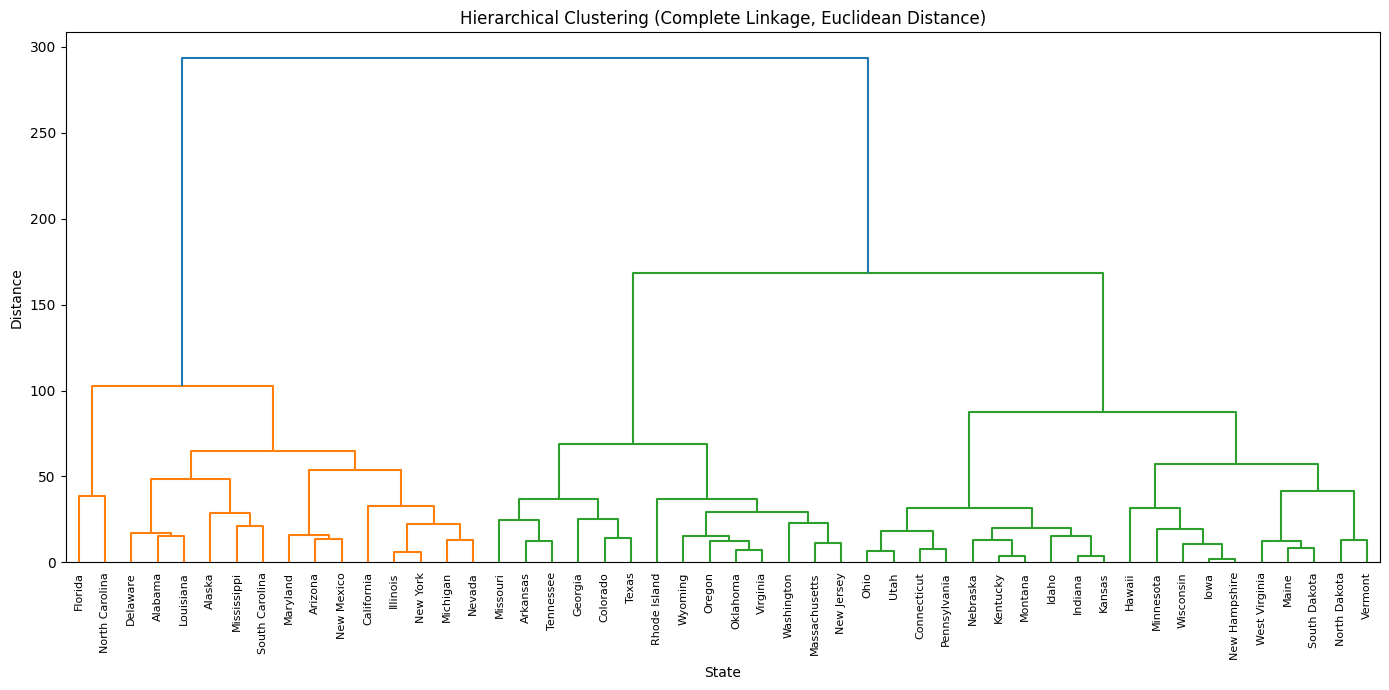

In [21]:
# imports
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# linkage and Euclidean distances
Z = linkage(X, method="complete", metric="euclidean")

# plot the dendrogram
fig, ax = plt.subplots(figsize=(14, 7))
dendrogram(Z, labels=states, leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set_title("Hierarchical Clustering (Complete Linkage, Euclidean Distance)")
ax.set_xlabel("State")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

2. Cut the dendrogram at a height that produces three clusters. Which states belong to each cluster?

In [22]:
# imports
from scipy.cluster.hierarchy import fcluster

# 3 clusters
labels = fcluster(Z, t=3, criterion="maxclust")

# print what states belong to each cluster
clusters = pd.DataFrame({"state": states, "cluster": labels})
for c in sorted(clusters["cluster"].unique()):
    members = clusters.loc[clusters["cluster"] == c, "state"].tolist()
    print(f"Cluster {c} ({len(members)} states): {', '.join(members)}")

Cluster 1 (16 states): Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina
Cluster 2 (14 states): Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming
Cluster 3 (20 states): Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin


3. Repeat the hierarchical clustering, again using complete linkage and Euclidean distance, after scaling all variables to have a standard deviation equal to one.

[-0.  0. -0.  0.]
[1. 1. 1. 1.]


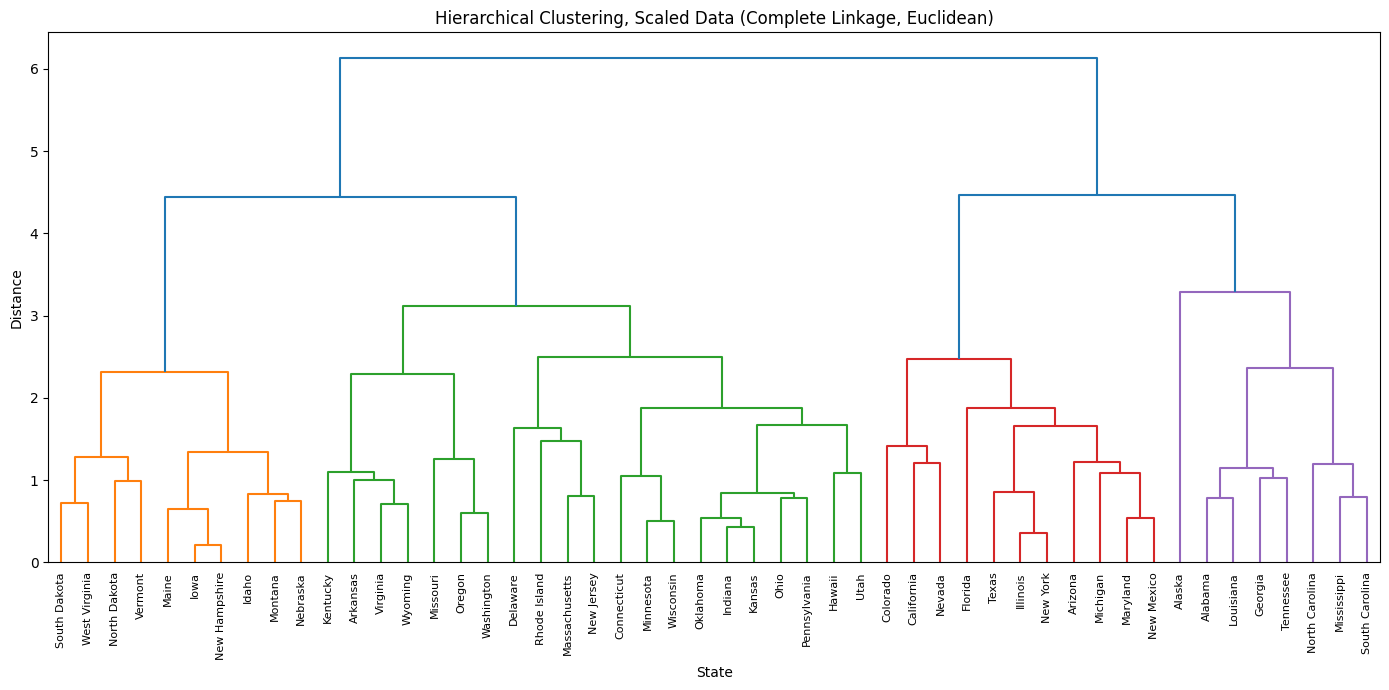

Cluster 1 (31 states): Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming
Cluster 2 (11 states): Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas
Cluster 3 (8 states): Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee


In [23]:
# import
from sklearn.preprocessing import StandardScaler

# scaling
X_scaled = StandardScaler().fit_transform(X)
# verify mean is 0 and std is 1
print(X_scaled.mean(axis=0).round(6))
print(X_scaled.std(axis=0))

# repeat
Z_scaled = linkage(X_scaled, method="complete", metric="euclidean")
fig, ax = plt.subplots(figsize=(14, 7))
dendrogram(Z_scaled, labels=states, leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set_title("Hierarchical Clustering, Scaled Data (Complete Linkage, Euclidean)")
ax.set_xlabel("State")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()
labels_scaled = fcluster(Z_scaled, t=3, criterion="maxclust")
clusters_scaled = pd.DataFrame({"state": states, "cluster": labels_scaled})
for c in sorted(clusters_scaled["cluster"].unique()):
    members = clusters_scaled.loc[clusters_scaled["cluster"] == c, "state"].tolist()
    print(f"Cluster {c} ({len(members)} states): {', '.join(members)}")

4. Compare the two clustering solutions. What effect does scaling the variables have on the resulting dendrogram and cluster memberships?
In your opinion, should the variables be scaled in this case before computing inter-observation dissimilarities? Provide a justification for your answer.

The first clustering solution had 16 states in the first cluster group, 14 in the next, and 20 in the last, making the split of states relatively even. The second clustering solution, after scaling, has 31 states in the first cluster group, 11 in the next, and 8 in the last, making the split of states relatively uneven. 

For effects on the dendrogram and cluster membership, the two dendrograms have differnt height scales. The unscaled merge distances reach about 300, while scaled distances reach about 6. In the unscaled dendrogram, most states join at low heights, with relatively few branches reaching the top. In the scaled dendrogram, merges are spread across mid and high heights. In both solutions, the first merge is between Iowa and New Hampshire. For cluster membership, 11 states changed groups. For the unstandardized cluster 1 group, after standardizing, majority landed in cluster 2, 9, then cluster 3, 6, and finally cluster 1, 1. So 7 states got moved. For the unstandardized cluster 2 group, after standardizing, majority landed in cluster 1, 10, then cluster 2, 2, and cluster 3, 2. So 4 states got moved. For the unstandardized cluster 3 group, after standardizing, all 20 landed in cluster 1, with none in cluster 2 or 3. So no state got moved. Overall, 11 states changed cluster membership with scaling (majority rule).

Note: A state was counted as changing groups if it was not in the scaled cluster that most of its original unscaled cluster’s states moved to. Cluster numbers are arbitrary across runs, so matching cluster numbers (1 → 1) don’t mean a state stayed in the same group.

I think the variables should be scaled before computing inter-observation dissimilarities becuase scaling the variables ensures every variable contributes equally to the dissimilarity matrix and the resulting dendrogram structure. In this dataset the 4 variables were measured in different units. Murder, Assault, and Rape were all per 100,000 residents but UrbanPop was a percentage. Euclidean distance adds squared differences across variables, so without scaling, the distances depend on those units and on each variable’s spread, not on how similar the states really are. Standardizing gives each variable a standard deviation of 1, so each contributes comparably to the dissimilarities. The trade-off is that the scaled three-cluster solution is lopsided (31/11/8), so the cut should be interpreted with that in mind.

## Part 2: Clustering, genomic data, and cancer (35 points)

Unsupervised techniques are often used to analyze genomic data. In particular, PCA and hierarchical clustering are popular tools.
You will apply these techniques to the dataset below, which consists of gene expression measurements for 64 cancer cell lines across 6,830 genes.

In [24]:
import pandas as pd
# dataset
X = pd.read_csv("Lab08-part2_data.csv")
# labels
y = pd.read_csv("Lab08-part2_labels.csv").label.to_numpy()

1. Perform hierarchical clustering of the data using complete, single, and average linkage. Use Euclidean distance as the distance metric in all three cases.

In [25]:
# imports
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import adjusted_rand_score

# number of clusters to cut each dendrogram into (matches the true number of classes)
k = len(np.unique(y))

methods = ["complete", "single", "average"]
linkages = {}
for method in methods:
    Z = linkage(X, method=method, metric="euclidean")
    linkages[method] = Z
    labels_pred = fcluster(Z, t=k, criterion="maxclust")
    ari = adjusted_rand_score(y, labels_pred)
    print(f"{method.capitalize():>8} linkage: adjusted Rand index = {ari:.4f}")

Complete linkage: adjusted Rand index = 0.3383
  Single linkage: adjusted Rand index = 0.0926
 Average linkage: adjusted Rand index = 0.2449


2. Plot the dendrogram for each linkage method. Briefly describe the structure of these dendrograms and comment on the main differences produced by the three linkage criteria.

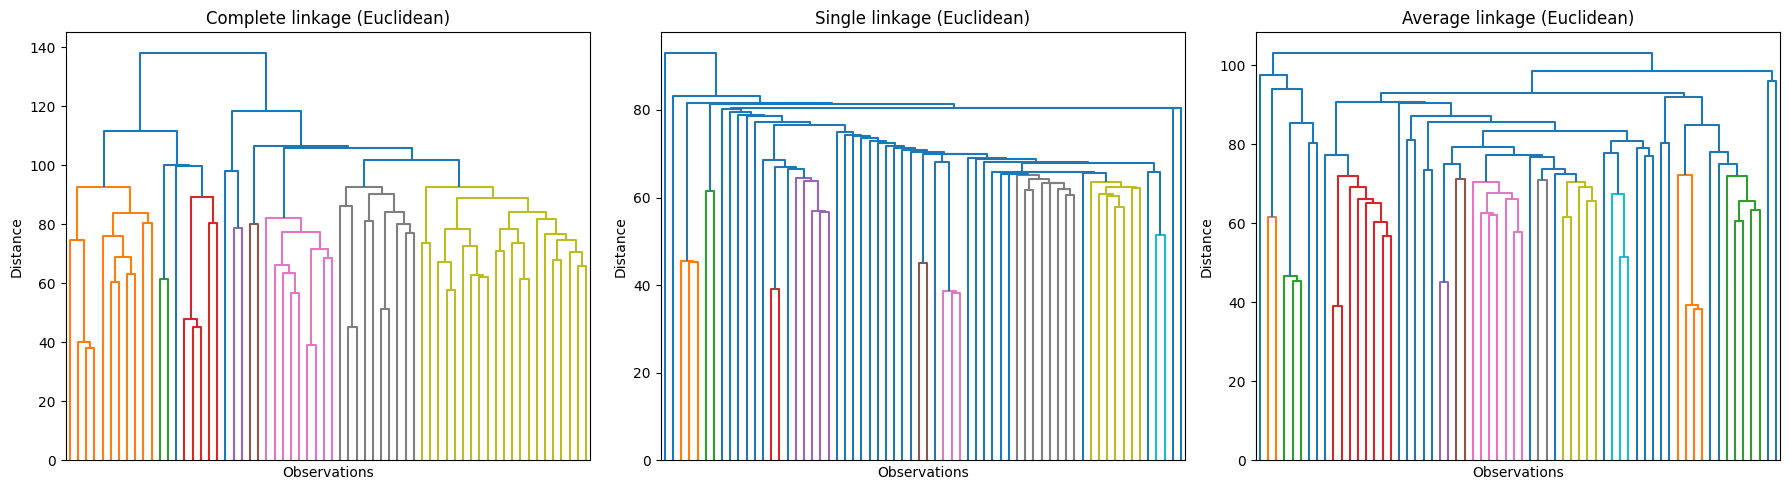

In [26]:
# imports
# Part 2: Plot the dendrogram for each linkage method
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, method in zip(axes, ["complete", "single", "average"]):
    dendrogram(linkages[method], ax=ax, no_labels=True)
    ax.set_title(f"{method.capitalize()} linkage (Euclidean)")
    ax.set_xlabel("Observations")
    ax.set_ylabel("Distance")

plt.tight_layout()
plt.show()

Question: Briefly describe the structure of these dendrograms and comment on the main differences produced by the three linkage criteria.


The three dendrograms vary quite a bit in structure. Complete linkage merges clusters based on their farthest pair of points, which creates smaller and more equally spread-out branches, with multiple subtrees. Single linkages merges clusters based on the closest pair of points, which produces a chaining effect, as the observations get added onto the same cluster. Average linkage merges based on the average distance between pairwise points, creating a decently balanced version with some small subtrees. 

3. Using the known cancer type labels and examining each dendrogram, qualitatively describe how well the samples cluster into distinct cancer types. Do you see clear separation between some types? Which ones appear more mixed?

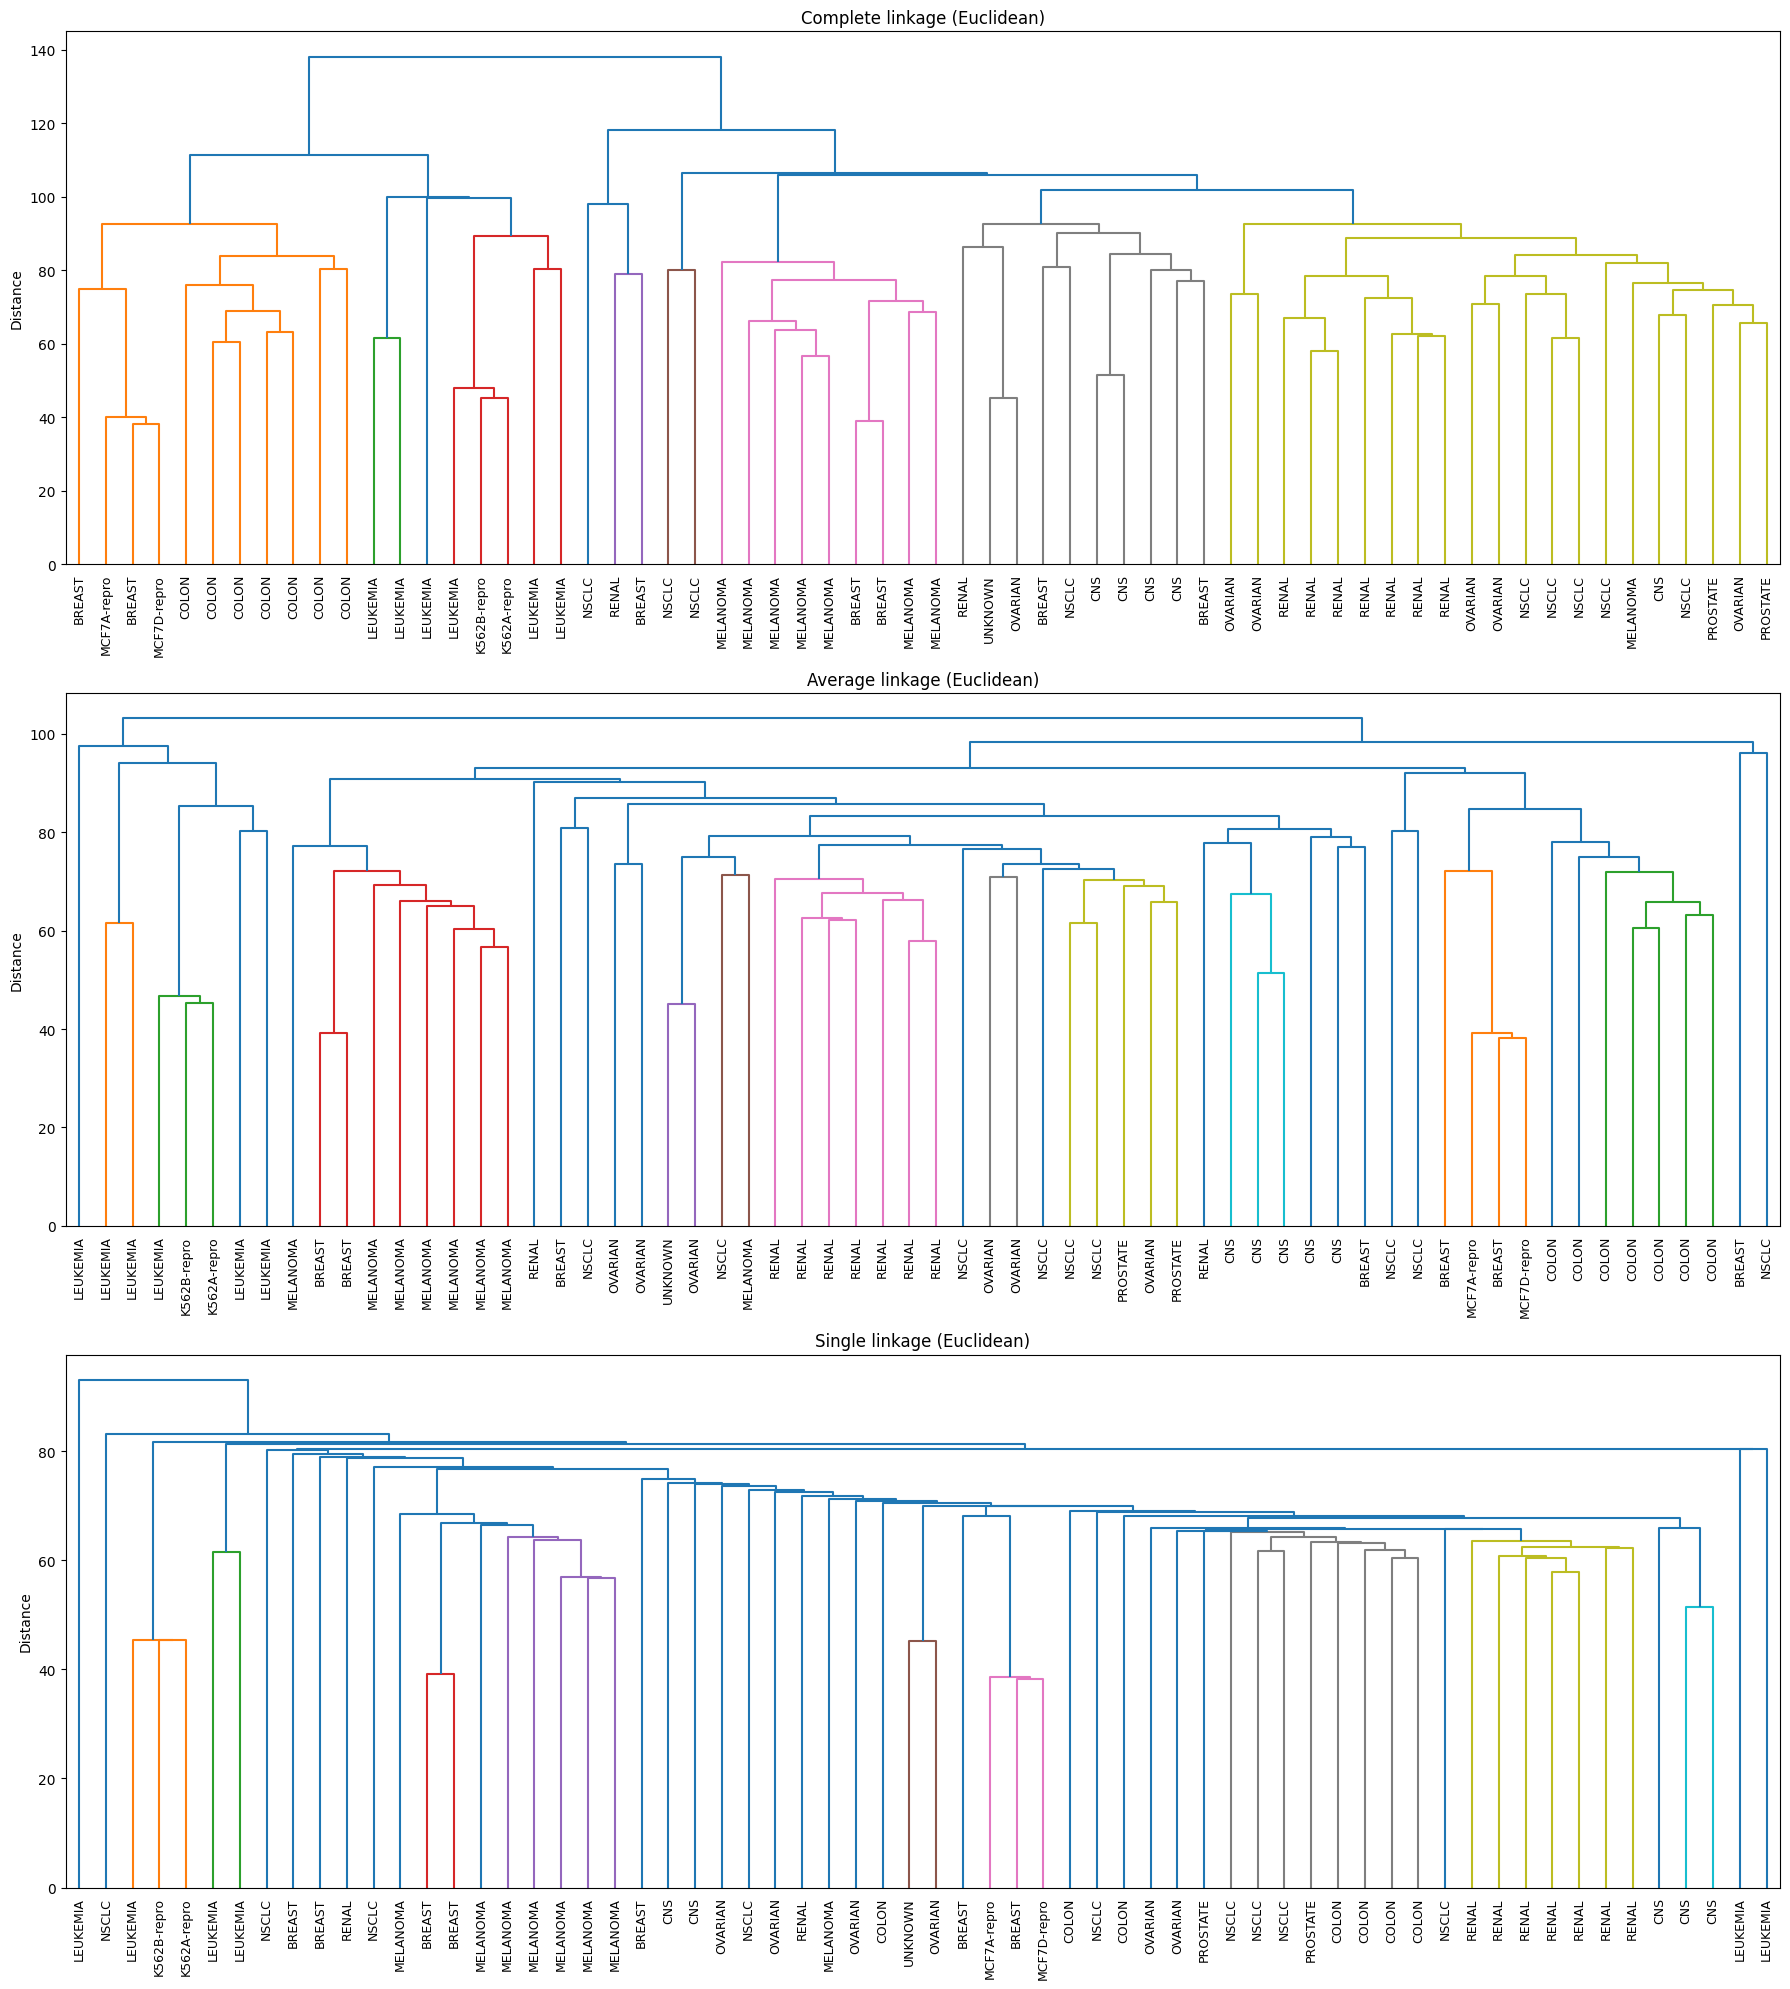

In [27]:
# add true cancer type labels to the dendrograms
fig, axes = plt.subplots(3, 1, figsize=(18, 20))
for ax, method in zip(axes, ["complete", "average", "single"]):
    dendrogram(linkages[method], labels=y, leaf_rotation=90, leaf_font_size=9, ax=ax)
    ax.set_title(f"{method.capitalize()} linkage (Euclidean)")
    ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

The samples don't sort neatly into all 14 cancer types, but a few types are pretty distinguishable. Leukemia and colon cell lines both cluster tightly around their own kind, while breast and lung cell lines are scatter across several branches and are mixed in with other cancer types, making those groups less distinguishable from one another. Complete linkage shows the structure best, while single linkage and average linkage lump most samples into one big cluster. 

4. Focusing on complete linkage, plot the dendrogram again and cut it to obtain 4 clusters (e.g., highlight or color the branches). Briefly describe which cancer cell lines cluster together (for example, which cancer types tend to appear in the same cluster). Compute internal validation scores for this 4-cluster partition (e.g., Silhouette score, Calinski–Harabasz index, Davies–Bouldin index).

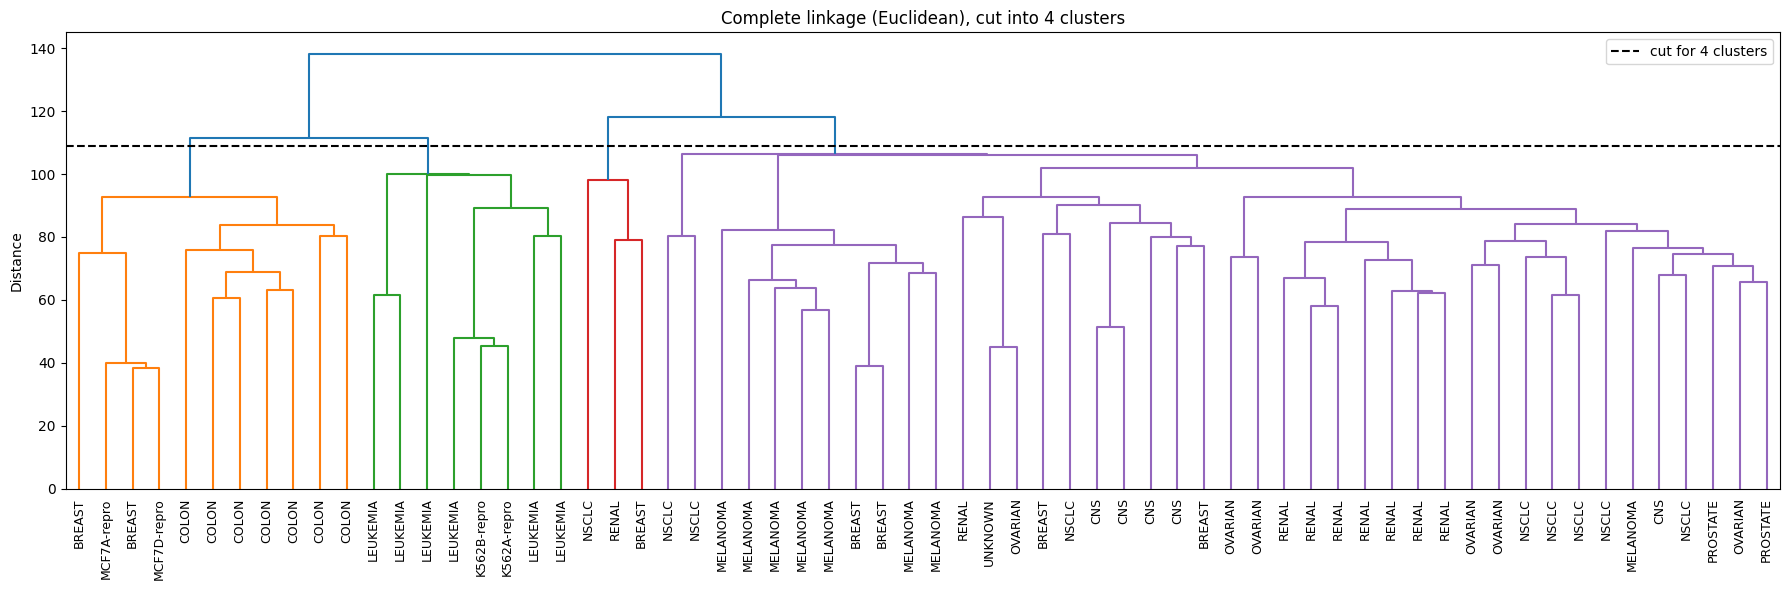

Cluster sizes: [11  8  3 42]
hierarchical cluster  1  2  3  4
cancer type                     
BREAST                2  0  1  4
CNS                   0  0  0  5
COLON                 7  0  0  0
K562A-repro           0  1  0  0
K562B-repro           0  1  0  0
LEUKEMIA              0  6  0  0
MCF7A-repro           1  0  0  0
MCF7D-repro           1  0  0  0
MELANOMA              0  0  0  8
NSCLC                 0  0  1  8
OVARIAN               0  0  0  6
PROSTATE              0  0  0  2
RENAL                 0  0  1  8
UNKNOWN               0  0  0  1

Silhouette: 0.0788
Calinski-Harabasz: 5.0103
Davies-Bouldin: 2.1683


In [28]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

Z = linkages["complete"]
# cut height to make exactly 4 clusters (between the 4th and 3rd last merges)
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2

# dendrogram
fig, ax = plt.subplots(figsize=(18, 6))
dendrogram(Z, labels=y, color_threshold=cut_height, leaf_rotation=90, leaf_font_size=9, ax=ax)
ax.axhline(cut_height, color="k", linestyle="--", label="cut for 4 clusters")
ax.set_title("Complete linkage (Euclidean), cut into 4 clusters")
ax.set_ylabel("Distance")
ax.legend()
plt.tight_layout()
plt.show()

# assign each observation to a cluster
hc4 = fcluster(Z, t=4, criterion="maxclust")
print("Cluster sizes:", np.bincount(hc4)[1:])
print(pd.crosstab(y, hc4, rownames=["cancer type"], colnames=["hierarchical cluster"]))

# clustering evaluation metrics
sil_h = silhouette_score(X, hc4)
ch_h = calinski_harabasz_score(X, hc4)
db_h = davies_bouldin_score(X, hc4)
print(f"\nSilhouette: {sil_h:.4f}")
print(f"Calinski-Harabasz: {ch_h:.4f}")
print(f"Davies-Bouldin: {db_h:.4f}")

Dividing up the complete linkage tree into 4 clusters creates groups of 11, 8, 3, and 42 cell lines. The first cluster groups all 7 colon cell lines with 4 breast cancer lines, while the second cluster groups all 6 leukemia lines with 2 K562 reproducibility lines. A very small cluster made up of 3 outliers was also created. The remaining 42 cell lines are grouped together and include most of the other cancer types. This suggests that this method does a good job of separating the more distinctive groups (colon, leukemia), but does not separate the remaining cancer types very well. The evaluation scores also show weak clustering overall, with the low Silhouette score (0.0788), the low Calinski-Harabasz score (5.0103), and the high Davies-Bouldin score (2.17). This shows that the clusters overlap and are not very well separated. 

5. Fit a K-Means model with 4 clusters to the same data. Compare this 4-cluster K-Means solution with the 4-cluster hierarchical solution from step 4. How similar are the two partitions? Use at least one external validation metric (e.g., Adjusted Rand Index) to quantify their agreement.

In [29]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# fit k-means with 4 clusters and compare
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
km4 = km.labels_
print("K-Means cluster sizes:", np.bincount(km4))
print("Hierarchical cluster sizes:", np.bincount(hc4)[1:])

# compare the 2 clustering methods
print("\nHierarchical (rows) vs K-Means (columns):")
print(pd.crosstab(hc4, km4, rownames=["hierarchical"], colnames=["k-means"]))

# compare k-means clusters against actual lables
print("\nK-Means: cancer type vs cluster")
print(pd.crosstab(y, km4, rownames=["cancer type"], colnames=["k-means"]))

# ARI scores
print(f"\nARI (hierarchical vs K-Means): {adjusted_rand_score(hc4, km4):.4f}")
print(f"ARI (K-Means vs true labels):  {adjusted_rand_score(y, km4):.4f}")
print(f"ARI (hierarchical vs true labels): {adjusted_rand_score(y, hc4):.4f}")

K-Means cluster sizes: [15 32  8  9]
Hierarchical cluster sizes: [11  8  3 42]

Hierarchical (rows) vs K-Means (columns):
k-means        0   1  2  3
hierarchical              
1             11   0  0  0
2              0   0  8  0
3              0   3  0  0
4              4  29  0  9

K-Means: cancer type vs cluster
k-means      0  1  2  3
cancer type            
BREAST       2  3  0  2
CNS          0  5  0  0
COLON        7  0  0  0
K562A-repro  0  0  1  0
K562B-repro  0  0  1  0
LEUKEMIA     0  0  6  0
MCF7A-repro  1  0  0  0
MCF7D-repro  1  0  0  0
MELANOMA     0  1  0  7
NSCLC        1  8  0  0
OVARIAN      3  3  0  0
PROSTATE     0  2  0  0
RENAL        0  9  0  0
UNKNOWN      0  1  0  0

ARI (hierarchical vs K-Means): 0.4490
ARI (K-Means vs true labels):  0.2272
ARI (hierarchical vs true labels): 0.1399


The two clustering methods have moderately similar results, with an ARI score of 0.4490, meaning that they group many observations similarly, but not exactly the same way. Both methods successfully identify the leukemia group and the small outlier group, while K-Means also identify the colon and breast cancer group but adds a few more observations to it. THe biggest difference is that K-Means splits the largest hierarchical cluster into three smaller groups, separating many of hte melanoma samples. This happens because K-Means tries to create more balanced clusters, while hierarchical clustering can be more affected by outliers. When compared to the actual cancer types, K-Means performs slightly better (ARI = 0.2272) than hierarchical (ARI = 0.1399), though both scores are pretty low. This is partly because there are 14 cancer types but only 4 clusters.

6. Genomic data can be noisy and high-dimensional. To address this, apply PCA to the original data and reduce it to the first 5 principal components. Then perform hierarchical clustering with complete linkage and Euclidean distance on this reduced 5-dimensional representation. Cut the resulting dendrogram to obtain 4 clusters.

Explained variance ratio: [0.1489 0.083  0.0658 0.0431 0.0385]
Total variance explained by 5 PCs: 0.3793


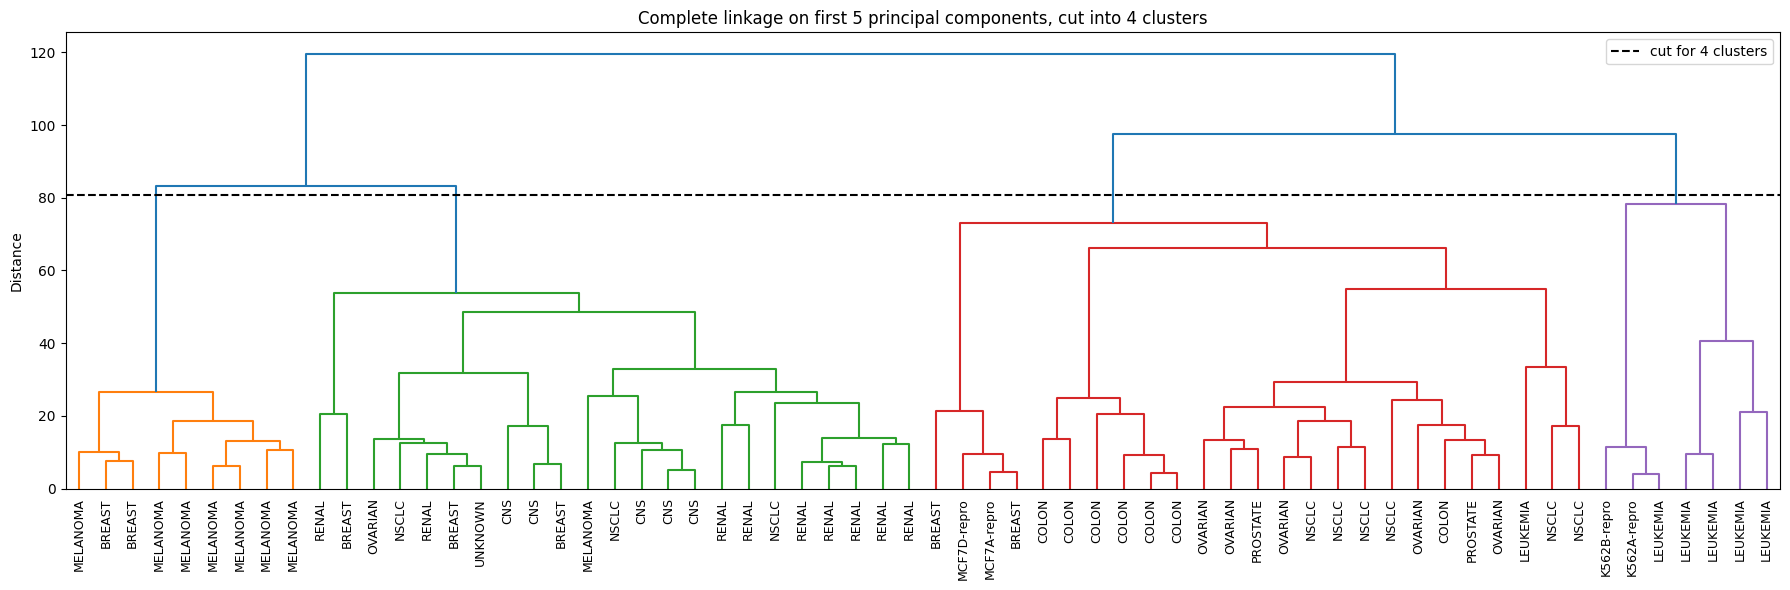

Cluster sizes: [ 9 23 25  7]
PCA-hierarchical cluster  1  2  3  4
cancer type                         
BREAST                    2  3  2  0
CNS                       0  5  0  0
COLON                     0  0  7  0
K562A-repro               0  0  0  1
K562B-repro               0  0  0  1
LEUKEMIA                  0  0  1  5
MCF7A-repro               0  0  1  0
MCF7D-repro               0  0  1  0
MELANOMA                  7  1  0  0
NSCLC                     0  3  6  0
OVARIAN                   0  1  5  0
PROSTATE                  0  0  2  0
RENAL                     0  9  0  0
UNKNOWN                   0  1  0  0


In [30]:
from sklearn.decomposition import PCA

# reduce data to first 5 principal components
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total variance explained by 5 PCs:", pca.explained_variance_ratio_.sum().round(4))

# hierarchical clustering using complete linkage
Z_pca = linkage(X_pca, method="complete", metric="euclidean")
cut_pca = (Z_pca[-4, 2] + Z_pca[-3, 2]) / 2

# dendrogram
fig, ax = plt.subplots(figsize=(18, 6))
dendrogram(Z_pca, labels=y, color_threshold=cut_pca, leaf_rotation=90, leaf_font_size=9, ax=ax)
ax.axhline(cut_pca, color="k", linestyle="--", label="cut for 4 clusters")
ax.set_title("Complete linkage on first 5 principal components, cut into 4 clusters")
ax.set_ylabel("Distance")
ax.legend()
plt.tight_layout()
plt.show()

# assign observations to clusters
hc4_pca = fcluster(Z_pca, t=4, criterion="maxclust")
print("Cluster sizes:", np.bincount(hc4_pca)[1:])
print(pd.crosstab(y, hc4_pca, rownames=["cancer type"], colnames=["PCA-hierarchical cluster"]))

7. Compute the internal validation metrics for this PCA-based 4-cluster solution. Do these values indicate better or worse quality than those obtained using the original (non-reduced) data? In addition, compare the agreement between the PCA-based partition and the original partition using at least one external validation metric. Comment on whether dimensionality reduction improved, worsened, or did not change the clustering quality.

In [31]:
# calculate internal clustering metrics in both the reduced and the original space
rows = {
    "Original data (step 4)": (silhouette_score(X, hc4), calinski_harabasz_score(X, hc4), davies_bouldin_score(X, hc4)),
    "PCA partition, PCA space": (silhouette_score(X_pca, hc4_pca), calinski_harabasz_score(X_pca, hc4_pca), davies_bouldin_score(X_pca, hc4_pca)),
    "PCA partition, original space": (silhouette_score(X, hc4_pca), calinski_harabasz_score(X, hc4_pca), davies_bouldin_score(X, hc4_pca)),
}
print(pd.DataFrame(rows, index=["Silhouette", "Calinski-Harabasz", "Davies-Bouldin"]).T.round(4))

# calculate external metrics using ARI to compare PCA clusters with the original ones
print(f"\nARI (PCA partition vs original partition): {adjusted_rand_score(hc4, hc4_pca):.4f}")
print(f"ARI (PCA partition vs true labels): {adjusted_rand_score(y, hc4_pca):.4f}")
print(f"ARI (original partition vs true labels): {adjusted_rand_score(y, hc4):.4f}")

                               Silhouette  Calinski-Harabasz  Davies-Bouldin
Original data (step 4)             0.0788             5.0103          2.1683
PCA partition, PCA space           0.3921            34.6806          0.9550
PCA partition, original space      0.1138             6.6705          2.2732

ARI (PCA partition vs original partition): 0.1961
ARI (PCA partition vs true labels): 0.2246
ARI (original partition vs true labels): 0.1399


Using PCA to reduce the data to just 5 principal components improved the clustering results. The silhouette score increased from 0.08 to 0.39, the Calinski-Harabasz score increased from 5.0 to 34.7, and the Davies-Bouldin score decreased from 2.17 to 0.96. This suggests that the clusters became more clearly separated. 

The PCA-based clusters also differ from the original clusters, with an ARI of only 0.20, meaning the dimensionality reduction changed the groupings. However, the PCA-based clustering matches the actual cancer types slightly better (ARI of 0.22 compared to 0.14). The new clusters are also more balanced, with sizes of 9, 23, 25, and 7.

Overall, the dimensionality reduction improved clustering quality since it reduced noise and focused more on the strong patterns in the data. However, the improvement wasn't super strong since the principal components could only explain some of the variation.

## Part 3: Clustering gene expression between healthy and diseased groups (35 points)

The following dataset contains gene expression measurements for 40 tissue samples, each measured on 1,000 genes. The first 20 samples come from healthy patients, while the second 20 samples come from a diseased group.

In [32]:
import pandas as pd
import numpy as np

X = pd.read_csv("Lab08-part3_data.csv") # This is the dataset to use
# We know that the first 20 observations correspond to healthy patients, and the remaining 20 to disease. Let's create labels then:
y = np.array(["healthy"]*20 + ["disease"]*20)

1. Apply hierarchical clustering to the samples using a correlation-based distance. Use complete, average, and single linkage. Plot the resulting dendrogram for each case.

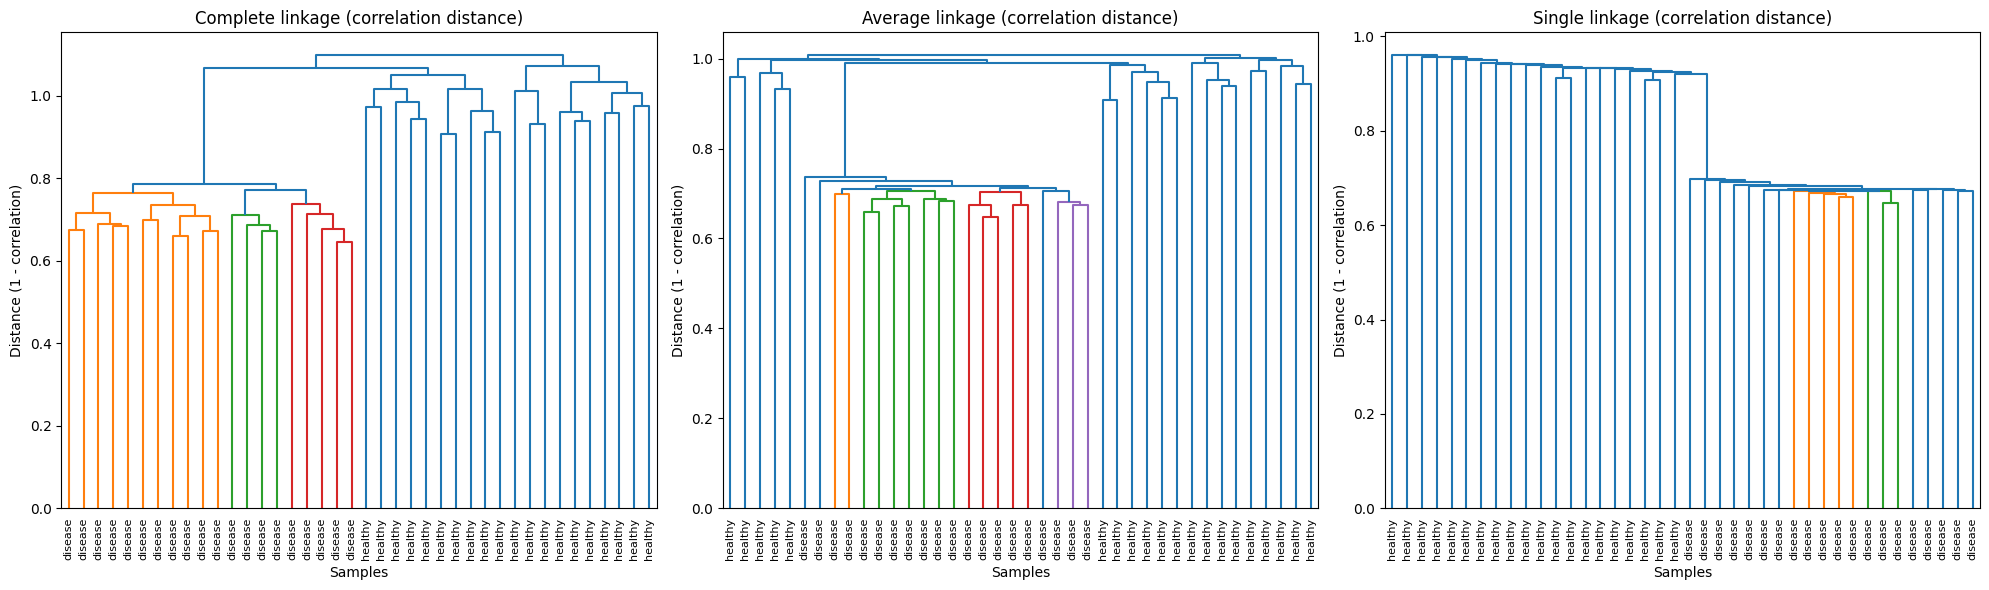

In [33]:
# imports 
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

# correlation-based distances
dist = pdist(X.values, metric="correlation")

methods = ["complete", "average", "single"]
linkages = {}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, method in zip(axes, methods):
    Z = linkage(dist, method=method)
    linkages[method] = Z
    dendrogram(Z, ax=ax, labels=y, leaf_rotation=90, leaf_font_size=8)
    ax.set_title(f"{method.capitalize()} linkage (correlation distance)")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Distance (1 - correlation)")
plt.tight_layout()
plt.show()

2. Looking at these dendrograms, which linkage criterion seems to provide better separation of the two groups?

ANSWER HERE!!

3. Why do you think you were not asked to use Ward linkage here?

4. Now, focusing on complete linkage, cut the dendrogram into 2 clusters. Compare this clustering with the known group labels using the Adjusted Rand Index.


5. Use a two-sample t-test (e.g., the `ttest_ind` function from `scipy.stats`) to compute a p-value for each gene assessing its ability to discriminate between the two groups. There are 1000 genes, so apply a Bonferroni correction by using a significance threshold of α/1000 (with α = 0.05). In other words, consider a gene statistically significant if its p-value is less than 0.05/1000. Select all genes that meet this criterion.

6. Reapply hierarchical clustering to the samples, again with complete linkage and correlation-based distance, but now using only the significant genes. Cut the tree into 2 clusters and compute the Adjusted Rand Index with respect to the known labels. Which clustering solution shows better agreement with the true groups?

7. In the previous step, you should observe that clustering using only the significant genes leads to worse agreement with the known labels than using all 1000 genes, even though these genes were selected for their discriminative ability. Now repeat the hierarchical clustering using complete linkage and Euclidean distance on the significant genes. Cut the dendrogram into 2 clusters and compare the results with the known labels. Why does Euclidean distance produce a much better reconstruction than correlation distance in this scenario?

## Part 4: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE